# 02 · Exploratory Data Analysis

**Goal:** describe customers, the outcome and the two experimental arms before estimating
any causal effect.

> **EDA describes patterns; it does not establish causality.** A segment with high churn among
> treated customers does not mean the treatment caused churn there. The segment may simply contain
> riskier customers, or a different share of them may have been treated. Causal claims start in
> notebook 03.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from src.functions import (AQUA, BLUE, GREY, INK_2, ORANGE, TREATMENT, OUTCOME, build_sqlite,
                           feature_lists, load_data, read_sql_queries, savefig, set_style,
                           weighted_smd)

set_style()
df = load_data()
num, cat = feature_lists(df)
t, y = df[TREATMENT].to_numpy(), df[OUTCOME].to_numpy()

## 1. Outcome and treatment distributions

In [2]:
ct = pd.crosstab(df[TREATMENT].map({0: "control", 1: "treated"}),
                 df[OUTCOME].map({0: "retained", 1: "churned"}), margins=True)
ct

y,churned,retained,All
t,,,
control,105,2781,2886
treated,303,8707,9010
All,408,11488,11896


Churn is rare (3.4%) in both arms, and three quarters of customers were treated. A bar chart of
these four numbers would add nothing to the table, so the arm comparison (with uncertainty) is
plotted once, in notebook 03.

## 2. Numeric features

The leading principal components capture most of the variance in the original numeric features.
Distributions are heavy-tailed, so the plots show the 1st–99th percentile range.

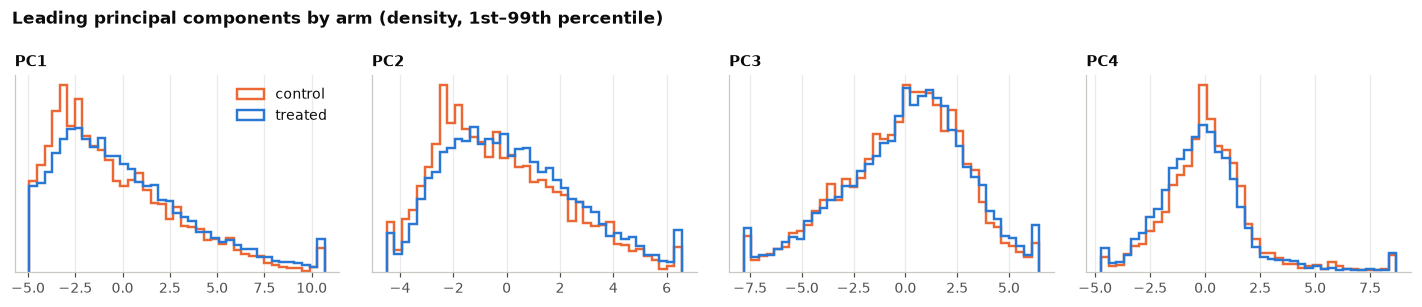

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8), sharey=False)
for ax, c in zip(axes, ["PC1", "PC2", "PC3", "PC4"]):
    lo, hi = df[c].quantile([0.01, 0.99])
    bins = np.linspace(lo, hi, 40)
    for arm, colour, label in [(0, ORANGE, "control"), (1, BLUE, "treated")]:
        ax.hist(df.loc[df[TREATMENT] == arm, c].clip(lo, hi), bins=bins, density=True,
                histtype="step", color=colour, linewidth=1.6, label=label)
    ax.set_title(c, fontsize=10)
    ax.set_yticks([])
axes[0].legend(loc="upper right")
fig.suptitle("Leading principal components by arm (density, 1st–99th percentile)", x=0.01,
             ha="left", fontsize=11, fontweight="bold")
plt.tight_layout()

The arms overlap closely on the leading components. Small shifts are visible, which is the first hint of
the imbalance quantified below.

## 3. Which features are associated with churn?

A simple *descriptive* screen: for each numeric feature, the AUC from using it alone to rank
churners above non-churners (0.5 = no association; values are folded so they are ≥ 0.5).
For each factor, the range of churn rates across levels with at least 100 customers.

In [4]:
auc = {c: roc_auc_score(y, df[c]) for c in num}
auc = pd.Series({c: max(a, 1 - a) for c, a in auc.items()}).sort_values(ascending=False)
print("Top numeric features by univariate churn AUC:")
print(auc.head(8).round(3).to_string())

fac = []
for c in cat:
    g = df.groupby(c)[OUTCOME].agg(["mean", "size"])
    g = g[g["size"] >= 100]
    fac.append({"factor": c, "levels(n≥100)": len(g),
                "min_churn": g["mean"].min(), "max_churn": g["mean"].max()})
fac = pd.DataFrame(fac).assign(range_pp=lambda d: 100 * (d.max_churn - d.min_churn))
fac.sort_values("range_pp", ascending=False).head(8).round(3)

Top numeric features by univariate churn AUC:
PC53     0.593
PC22     0.578
PC15     0.567
PC18     0.566
PC135    0.563
PC47     0.563
PC14     0.562
PC31     0.561


,factor,levels(n≥100),min_churn,max_churn,range_pp
12,FACTOR15,11,0.000,0.070,7.018
4,FACTOR6,20,0.008,0.064,5.631
1,FACTOR2,5,0.008,0.043,3.408
0,FACTOR1,10,0.021,0.050,2.934
13,FACTOR16,16,0.017,0.044,2.736
10,FACTOR13,11,0.023,0.047,2.369
8,FACTOR11,3,0.034,0.056,2.229
2,FACTOR4,10,0.024,0.046,2.124


Individually, features are only weakly associated with churn (the best single component has an
AUC of about 0.59), but churn rates differ by up to 7 percentage points across factor levels. In
combination, the features make churn quite **predictable**: the multivariate churn model in
notebook 06 reaches an out-of-sample AUC of about 0.85.
Prediction answers "who is likely to churn?", which is **not** the causal question. A customer
can be very likely to churn and yet unaffected by a retention call.

## 4. Treatment vs control: are the arms comparable?

The standardised mean difference (SMD) compares each covariate's mean between arms in
pooled-SD units. A common rule of thumb flags |SMD| > 0.1 as meaningful imbalance.

In [5]:
Xd = pd.concat([df[num], pd.get_dummies(df[cat], prefix_sep="=").astype(float)], axis=1)
smd = weighted_smd(Xd, t)
print(f"Covariates (incl. one-hot levels): {len(smd)}")
print(f"|SMD| > 0.1: {(smd.abs() > 0.1).sum()}   max |SMD| = {smd.abs().max():.3f}")
smd.abs().sort_values(ascending=False).head(10).round(3)

Covariates (incl. one-hot levels): 331
|SMD| > 0.1: 20   max |SMD| = 0.364


FACTOR18=V7    0.364
FACTOR4=V10    0.314
PC8            0.220
FACTOR6=V10    0.189
FACTOR18=V2    0.178
PC28           0.168
FACTOR4=V7     0.163
FACTOR18=V4    0.147
FACTOR4=V12    0.145
FACTOR2=V10    0.132
Name: smd, dtype: float64

Twenty covariates exceed the 0.1 threshold. The largest are levels of `FACTOR18`, `FACTOR4` and
`FACTOR6`, plus a few components (e.g. `PC8`, `PC28`). With ~2,900 control customers, chance imbalance this large across a few hundred
covariates is unlikely, so the pattern is systematic. Combined with notebook 01's finding that
the treated share ranges from 63% to 86% across segments, this suggests the pooled
campaigns used **different treatment ratios for different customer segments**.

## 5. SQL: segment-level summary

The same checks expressed in SQL, as they would typically be run against a customer database.
The data is loaded into an in-memory SQLite database with two tables, `customers`
(attributes) and `campaign` (experiment log), joined on `customer_id`. The queries live in
[`sql/customer_summary.sql`](../sql/customer_summary.sql).

In [6]:
conn = build_sqlite(df)
queries = read_sql_queries()
print(queries["segment_assignment"])

-- Join attributes to the experiment log and summarise each segment of a factor:
-- share treated, churn by arm, and the raw (unadjusted) churn difference.
-- Segments with fewer than 100 customers are filtered out with HAVING.
SELECT
    c.FACTOR18                                                   AS segment,
    COUNT(*)                                                     AS customers,
    ROUND(AVG(e.t), 3)                                           AS treated_share,
    ROUND(AVG(CASE WHEN e.t = 0 THEN e.y END), 4)                AS churn_control,
    ROUND(AVG(CASE WHEN e.t = 1 THEN e.y END), 4)                AS churn_treated,
    ROUND(AVG(CASE WHEN e.t = 1 THEN e.y END)
        - AVG(CASE WHEN e.t = 0 THEN e.y END), 4)                AS raw_difference
FROM customers AS c
JOIN campaign  AS e USING (customer_id)
GROUP BY c.FACTOR18
HAVING COUNT(*) >= 100
ORDER BY treated_share;


In [7]:
pd.read_sql(queries["arm_summary"], conn)

,arm,customers,churners,churn_rate
0,control,2886,105,0.0364
1,treated,9010,303,0.0336


In [8]:
seg = pd.read_sql(queries["segment_assignment"], conn)
seg

,segment,customers,treated_share,churn_control,churn_treated,raw_difference
0,V6,526,0.643,0.0319,0.0473,0.0154
1,V2,2300,0.689,0.0349,0.0259,-0.0090
2,V1,175,0.709,0.0784,0.0323,-0.0462
3,V4,3375,0.714,0.0393,0.0357,-0.0036
4,V7,5388,0.829,0.0336,0.0345,0.0009


In [9]:
pd.read_sql(queries["usage_band_churn"], conn)

,pc1_quartile,customers,churn_control,churn_treated
0,1,2974,0.0365,0.0306
1,2,2974,0.0218,0.0299
2,3,2974,0.0393,0.0277
3,4,2974,0.0500,0.0458


The `segment_assignment` query reproduces the pandas result. `FACTOR18 = V7` (45% of customers)
was treated at 83%, the other segments at 64–71%. The raw treated-minus-control differences
within segments vary in sign and size. With ~100–1,000 control customers per segment, those
differences are mostly noise at this stage.

## 6. Figure: treatment share and churn by segment

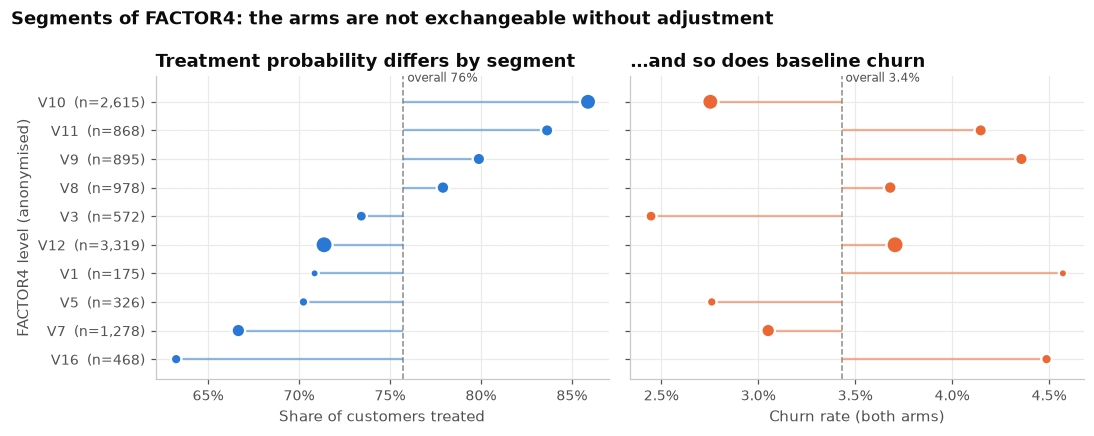

In [10]:
seg4 = (df.groupby("FACTOR4")
          .agg(customers=(TREATMENT, "size"), treated_share=(TREATMENT, "mean"), churn=(OUTCOME, "mean"))
          .query("customers >= 100").sort_values("treated_share"))
overall_share, overall_churn = t.mean(), y.mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ypos = np.arange(len(seg4))
a1.axvline(overall_share, color=GREY, linewidth=1, linestyle="--")
a1.hlines(ypos, overall_share, seg4.treated_share, color=BLUE, linewidth=1.5, alpha=0.5)
a1.scatter(seg4.treated_share, ypos, s=np.sqrt(seg4.customers) * 2.2, color=BLUE, zorder=3,
           edgecolor="white", linewidth=1.5)
a1.set_xlabel("Share of customers treated")
a1.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
a1.text(overall_share, len(seg4) - 0.4, f" overall {overall_share:.0%}", color=INK_2, fontsize=8, va="bottom")
a1.set_title("Treatment probability differs by segment")

a2.axvline(overall_churn, color=GREY, linewidth=1, linestyle="--")
a2.hlines(ypos, overall_churn, seg4.churn, color=ORANGE, linewidth=1.5, alpha=0.5)
a2.scatter(seg4.churn, ypos, s=np.sqrt(seg4.customers) * 2.2, color=ORANGE, zorder=3,
           edgecolor="white", linewidth=1.5)
a2.set_xlabel("Churn rate (both arms)")
a2.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=1))
a2.text(overall_churn, len(seg4) - 0.4, f" overall {overall_churn:.1%}", color=INK_2, fontsize=8, va="bottom")
a2.set_title("…and so does baseline churn")

a1.set_yticks(ypos, [f"{lvl}  (n={n:,})" for lvl, n in zip(seg4.index, seg4.customers)])
a1.set_ylabel("FACTOR4 level (anonymised)")
a1.set_ylim(-0.7, len(seg4) - 0.1)
fig.suptitle("Segments of FACTOR4: the arms are not exchangeable without adjustment",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
savefig(fig, "fig2_segment_assignment")

**Reading the figure.** Each dot is a level of the anonymised `FACTOR4` (dot area ∝ customers).
Segments differ both in how likely their customers were to be treated (63–86%) and in how often
they churn. When treatment probability and baseline churn both vary across segments, the pooled
treated-vs-control comparison can mix the effect of the call with differences in *who* was called.
That is the definition of confounding. Here the variation in churn across segments is modest and not
systematically aligned with treatment share, so the bias is probably small. Notebook 03
checks this formally rather than assuming it.

## Summary

* Churn is rare (408 events) and **predictable** from the covariates.
* The two arms are **not perfectly balanced**: treatment probability depends on segment
  (`FACTOR4`, `FACTOR18`, `FACTOR6`), which is consistent with pooling campaigns that used different
  treatment/control ratios.
* None of these patterns are causal statements. The next notebook estimates the treatment effect
  with and without adjustment for the assignment mechanism.